# 7 · Resampling in time

Changing the time step of a forecast is where units go quietly wrong. `Resample` makes the
contract explicit, and this notebook checks it against real files rather than asserting it.

The one rule everything follows: a value stamped at *t* describes the interval
**`[t, t + step)`** — the stamp **opens** the window. Sources that stamp an accumulation at
the *end* of its interval (ERA5 does) must be shifted by you before resampling.

**Needs:** core dependencies, plus `matplotlib`. Section 5 also needs GDAL, like notebook 6.

In [1]:
import importlib.util
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Environment noise, nothing to do with meteoraster: xarray probes every NetCDF/GRIB
# backend it can find (cfgrib needs the ecCodes binary), and this conda env's h5py and
# HDF5 builds differ by a patch release.
warnings.filterwarnings('ignore', message='(?s).*ecCodes.*')
warnings.filterwarnings('ignore', message='(?s).*h5py is running against HDF5.*')

# Report warnings without their absolute path, so the committed output does not carry
# one machine's directory layout. The warnings themselves stay visible.
def brief_warning(message, category, filename, lineno, line=None):
    return '%s:%d: %s: %s\n' % (Path(filename).name, lineno, category.__name__, message)


warnings.formatwarning = brief_warning

# Run straight from a clone: if `meteoraster` is not installed in this environment,
# fall back to the repository root one level up.
if importlib.util.find_spec('meteoraster') is None:
    sys.path.insert(0, str(Path('..').resolve()))

from meteoraster import MeteoRaster, Resample

RESOURCES = Path('..') / 'tests' / 'resources'

plt.rcParams['figure.dpi'] = 100
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 12)

print('Resample version', Resample.VERSION, ' types:', Resample.TYPES)

Resample version 2.1  types: ('sum', 'mean', 'linear', 'max')


`Resample.resample` works on a **DataFrame**, not on a raster: rows are production
timestamps, and the columns must carry a `leadtime` level. Any other column level (a
variable, a station, a catchment) is a *header* and is carried along untouched. Notebooks 5
and 6 both produce exactly that shape.

---

## 1 · The four types, on four numbers

Four daily values, one leadtime column. Small enough to check by eye.

In [2]:
index = pd.date_range('2023-01-01', periods=4, freq='D')
columns = pd.MultiIndex.from_tuples([('demo', pd.Timedelta(0))], names=['series', 'leadtime'])
daily = pd.DataFrame([[1.0], [2.0], [3.0], [4.0]], index=index, columns=columns)

daily

series,demo
leadtime,0 days
2023-01-01,1.0
2023-01-02,2.0
2023-01-03,3.0
2023-01-04,4.0


### Down-sampling: 1 day → 2 days

In [3]:
down = pd.DataFrame(
    {kind: Resample.resample(daily, '2D', kind).iloc[:, 0] for kind in Resample.TYPES})
down

,sum,mean,linear,max
2023-01-01,3.0,1.5,1.0,2.0
2023-01-03,7.0,3.5,3.0,4.0


| type | what it did | why |
|---|---|---|
| `sum` | `1+2`, `3+4` | the value is a **total per step** — totals add |
| `mean` | `(1+2)/2`, `(3+4)/2` | the value is an **interval average** — averages are time-weighted |
| `linear` | `1`, `3` | the value is an **instant** — sample it at the new stamp |
| `max` | `2`, `4` | the value is an **extreme** — take the extreme |

### Up-sampling: 1 day → 6 hours

In [4]:
up = pd.DataFrame(
    {kind: Resample.resample(daily, '6h', kind).iloc[:, 0] for kind in Resample.TYPES})
up.head(8)

,sum,mean,linear,max
2023-01-01 00:00:00,0.25,1.0,1.00,1.0
2023-01-01 06:00:00,0.25,1.0,1.25,1.0
2023-01-01 12:00:00,0.25,1.0,1.50,1.0
2023-01-01 18:00:00,0.25,1.0,1.75,1.0
2023-01-02 00:00:00,0.50,2.0,2.00,2.0
2023-01-02 06:00:00,0.50,2.0,2.25,2.0
2023-01-02 12:00:00,0.50,2.0,2.50,2.0
2023-01-02 18:00:00,0.50,2.0,2.75,2.0


The same four semantics, run backwards:

- `sum` **splits** each daily total into four equal quarters — `1` becomes `0.25 × 4`. Mass
  is conserved, and *that is the point*: the number changes because the accumulation period
  changed. mm stays mm, but mm/day became mm/6h.
- `mean` and `max` **replicate** — the interval average of a sub-interval is the parent's
  average; so is its maximum, absent finer information.
- `linear` **interpolates** between stamps, because it describes an instant.

> **This is the whole decision.** Is your variable *extensive* — a total accumulated over
> the step (mm, J/m²)? Use `sum`. Or *intensive* — a rate or a state that does not depend
> on how long the step is (°C, m/s, W/m², mm/h)? Use `mean`, `linear` or `max`.
> The same physical quantity needs `sum` when stored as an accumulation and `mean` when
> stored as a rate. Choosing wrong is silent.

---
## 2 · Mass conservation, on a real forecast

NOAA GFS precipitation over Belgium: 3-hourly accumulations in `mm/3h`, so `sum`. Pull a
point series out (notebook 5) and take it to a daily step.

In [5]:
rain = MeteoRaster.load(RESOURCES / 'tethys_NOAA_GFS_0.25_2026.02.02.nct', verbose=False)
point = rain.get_values_from_latlon(lat=50.5, lon=5.9)

print('input :', point.shape, ' units', rain.units, ' columns', point.columns.names)

to_daily = Resample.resample(point, '1D', 'sum')
print('output:', to_daily.shape, ' columns', to_daily.columns.names)
print('\nthe leadtime level is renamed "delay" on output')

input : (7, 129)  units mm/3h  columns ['leadtime', 'ensemble_member']
output: (7, 16)  columns ['ensemble_member', 'delay']

the leadtime level is renamed "delay" on output


meteoraster.py:830: RuntimeWarning: Mean of empty slice


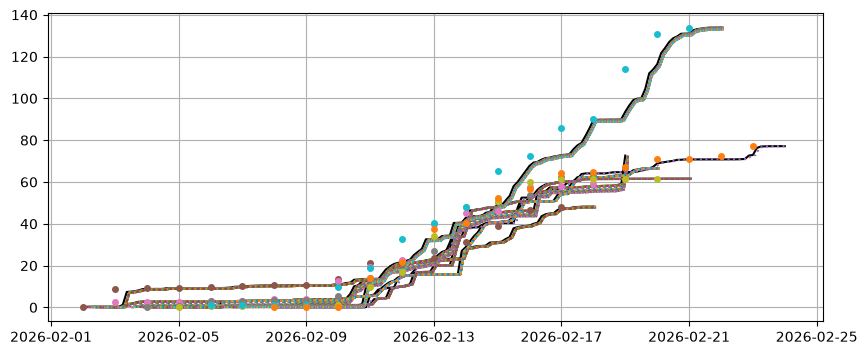

In [77]:
def plot_datetimes(df, cumulative=False, droplevel=[], ax=None, **plot_kwargs):
    """Plot the cumulative sum of a DataFrame with a MultiIndex."""

    tmp = df.copy()
    if droplevel:
        tmp = tmp.droplevel(droplevel, axis=1)
    if cumulative:
        tmp = tmp.cumsum(axis=1)

    for i, r in tmp.iterrows():
        t_ = i + r.index
        if ax is None:
            plt.plot(t_, r.values, label=i, **plot_kwargs)
        else:
            ax.plot(t_, r.values, label=i, **plot_kwargs)

plt.figure(figsize=(10, 4))
ax = plt.subplot(1, 1, 1)
plot_datetimes(point, droplevel=['ensemble_member'], cumulative=True, ax=ax, color='k')
plot_datetimes(Resample.resample(point, '1H', 'sum'), droplevel=['ensemble_member'], cumulative=True, ax=ax, linestyle=':')
plot_datetimes(to_daily, droplevel=['ensemble_member'], cumulative=True, ax=ax, marker='o', markersize=4, linestyle='None')
plt.grid()

The first day of the first forecast is eight 3-hourly values. They should add up to the
first daily value, exactly:

In [6]:
issue = point.index[0]
leads = pd.to_timedelta(point.columns.get_level_values('leadtime'))

check = pd.DataFrame({
    'leadtime': leads[:8],
    'valid from': [issue + lead for lead in leads[:8]],
    'mm/3h': point.iloc[0, :8].values,
})
check.loc['total'] = ['', '', check['mm/3h'].sum()]
print('daily value from Resample: %.4f mm' % to_daily.iloc[0, 0])
check

daily value from Resample: 0.3456 mm


,leadtime,valid from,mm/3h
0,0 days 00:00:00,2026-02-02 00:00:00,0.11232
1,0 days 03:00:00,2026-02-02 03:00:00,0.19872
2,0 days 06:00:00,2026-02-02 06:00:00,0.03456
3,0 days 09:00:00,2026-02-02 09:00:00,0.00000
4,0 days 12:00:00,2026-02-02 12:00:00,0.00000
5,0 days 15:00:00,2026-02-02 15:00:00,0.00000
6,0 days 18:00:00,2026-02-02 18:00:00,0.00000
7,0 days 21:00:00,2026-02-02 21:00:00,0.00000
total,,,0.34560


### The caveat that catches people

The output covers `horizon // timestep` **whole** steps, so a target step that does not
divide the horizon truncates the tail. Compare the totals:

In [7]:
print('sum of the 129 three-hourly values : %.4f mm' % np.nansum(point.iloc[0].values))
print('sum of the 16 daily values         : %.4f mm' % np.nansum(to_daily.iloc[0].values))
print('difference                         : %.4f mm  <- the partial window past 16 days'
      % (np.nansum(point.iloc[0].values) - np.nansum(to_daily.iloc[0].values)))

sum of the 129 three-hourly values : 48.1982 mm
sum of the 16 daily values         : 48.1766 mm
difference                         : 0.0216 mm  <- the partial window past 16 days


So check mass conservation **against the fine grid aggregated in blocks**, never against
the input total. Nothing is lost, it is simply outside the output grid.

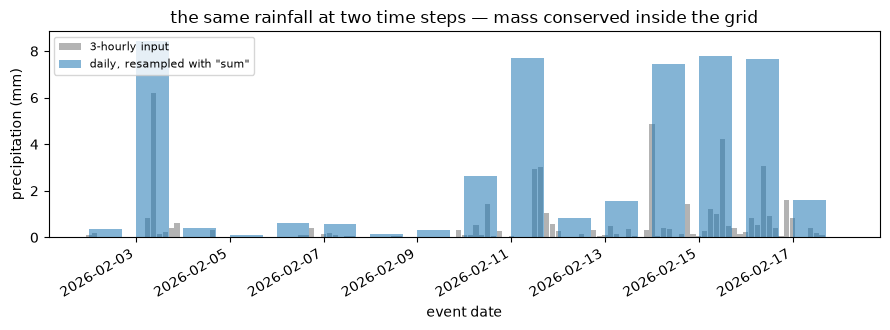

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.4))

ax.bar([issue + lead for lead in leads], point.iloc[0].values,
       width=0.11, color='0.7', label='3-hourly input')
ax.bar([issue + d for d in pd.to_timedelta(to_daily.columns.get_level_values('delay'))],
       to_daily.iloc[0].values, width=0.7, alpha=0.55, color='tab:blue', align='edge',
       label='daily, resampled with "sum"')

ax.set(xlabel='event date', ylabel='precipitation (mm)',
       title='the same rainfall at two time steps — mass conserved inside the grid')
ax.legend(fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()

---
## 3 · Leadtimes that are not evenly spaced

Operational forecasts get coarser as they look further ahead: hourly for the first days,
then 3-hourly, then 6-hourly. The IPMA fixture does exactly that.

In [9]:
ipma = MeteoRaster.load(RESOURCES / 'tethys_ipma_tp_20260814.nct', verbose=False)
ipma_leads = pd.to_timedelta(ipma.leadtimes)

spacing = pd.Series(np.diff(ipma_leads)).value_counts().sort_index()
print('%d leadtimes, from %s to %s\n' % (len(ipma_leads), ipma_leads[0], ipma_leads[-1]))
spacing.rename('columns at this spacing').to_frame()

120 leadtimes, from 0 days 01:00:00 to 10 days 00:00:00



,columns at this spacing
0 days 01:00:00,83
0 days 03:00:00,20
0 days 06:00:00,16


Each column spans the distance to the next one; the last reuses the span before it. So the
120 columns are 120 windows of three different widths, laid end to end.

In [10]:
ipma_point = ipma.get_values_from_latlon(lat=39.0, lon=-8.0)

fine = Resample.resample(ipma_point, '1h', 'sum')
coarse = Resample.resample(ipma_point, '6h', 'sum')

pd.DataFrame({
    'columns': [ipma_point.shape[1], fine.shape[1], coarse.shape[1]],
    'total (mm)': [np.nansum(ipma_point.values), np.nansum(fine.values), np.nansum(coarse.values)],
}, index=['input (1 h / 3 h / 6 h mixed)', 'resampled to 1 h', 'resampled to 6 h']).round(4)

,columns,total (mm)
input (1 h / 3 h / 6 h mixed),120,18.9385
resampled to 1 h,245,18.9385
resampled to 6 h,40,18.5157


**Up-sampling to 1 h conserves the mass exactly**, across a grid whose source spacing
changes twice. Down-sampling to 6 h loses the tail past the last whole window, as in
section 2 — not the spacing change.

Note the output stamps start at **1 h**, not 0, because that is where this forecast starts:

In [11]:
print('first output delays:', [str(d) for d in coarse.columns.get_level_values('delay')[:4]])

first output delays: ['0 days 01:00:00', '0 days 07:00:00', '0 days 13:00:00', '0 days 19:00:00']


### Which source columns feed one output window

This is the machinery. For each output window `[a, b)`, every source column contributes the
fraction of *its own span* that falls inside — so a 6 h source column straddling two output
windows splits 5/6 – 1/6 between them, and `sum` still conserves mass.

The table below recomputes that by hand and checks it against what `Resample` returned.

In [12]:
lead_h = ipma_leads.total_seconds().values / 3600.0
spans = np.diff(lead_h, append=lead_h[-1] + (lead_h[-1] - lead_h[-2]))
values = ipma_point.iloc[0].values
out_h = coarse.columns.get_level_values('delay').total_seconds().values / 3600.0


def window_table(k):
    """Every source column overlapping output window k, and its contribution."""
    a, b = out_h[k], out_h[k] + 6.0
    overlap = np.clip(np.minimum(lead_h + spans, b) - np.maximum(lead_h, a), 0, None)
    hit = overlap > 0
    contribution = values[hit] * overlap[hit] / spans[hit]

    print('output window %d: leadtime %.0f h to %.0f h   |   by hand %.5f mm, Resample %.5f mm'
          % (k, a, b, contribution.sum(), coarse.iloc[0, k]))

    return pd.DataFrame({
        'source leadtime (h)': lead_h[hit],
        'its span (h)': spans[hit],
        'inside the window (h)': overlap[hit],
        'fraction used': (overlap[hit] / spans[hit]).round(4),
        'value (mm)': values[hit].round(5),
        'contributes (mm)': contribution.round(5),
    })


window_table(0)

output window 0: leadtime 1 h to 7 h   |   by hand 0.01121 mm, Resample 0.01121 mm


,source leadtime (h),its span (h),inside the window (h),fraction used,value (mm),contributes (mm)
0,1.0,1.0,1.0,1.0,0.00000,0.00000
1,2.0,1.0,1.0,1.0,0.00000,0.00000
2,3.0,1.0,1.0,1.0,0.00000,0.00000
3,4.0,1.0,1.0,1.0,0.00000,0.00000
4,5.0,1.0,1.0,1.0,0.00095,0.00095
5,6.0,1.0,1.0,1.0,0.01025,0.01025


Six hourly columns, each entirely inside the window. Now one from the 3-hourly stretch:

In [13]:
window_table(15)

output window 15: leadtime 91 h to 97 h   |   by hand 0.41739 mm, Resample 0.41739 mm


,source leadtime (h),its span (h),inside the window (h),fraction used,value (mm),contributes (mm)
0,90.0,3.0,2.0,0.6667,0.20885,0.13924
1,93.0,3.0,3.0,1.0000,0.20885,0.20885
2,96.0,3.0,1.0,0.3333,0.20790,0.06930


And one from the 6-hourly stretch, where the output grid is *offset* from the source grid —
two columns split it 5/6 and 1/6:

In [14]:
window_table(25)

output window 25: leadtime 151 h to 157 h   |   by hand 0.34078 mm, Resample 0.34078 mm


,source leadtime (h),its span (h),inside the window (h),fraction used,value (mm),contributes (mm)
0,150.0,6.0,5.0,0.8333,0.32806,0.27339
1,156.0,6.0,1.0,0.1667,0.40436,0.06739


The internal working grid is the exact `gcd` of the production, leadtime and target steps,
which is why non-integer ratios are not truncated and why an all-daily frame does not
inflate to an hourly grid.

---
## 4 · Two data models, one method

How many leadtime columns the frame has decides what `resample` is being asked to do.

**Several leadtime columns → a forecast.** Production times are never mixed with each
other; only leadtimes are aggregated. An output stamp that falls between two issues reuses
the latest available forecast, with its leadtimes shifted to match.

In [15]:
six_hourly = Resample.resample(point, '6h', 'sum')

print('output rows:', six_hourly.shape[0], 'at 6 h spacing over the 7 daily issues')
six_hourly.iloc[:3, :4].round(4)

output rows: 25 at 6 h spacing over the 7 daily issues


ensemble_member                   0                                                
delay               0 days 00:00:00 0 days 06:00:00 0 days 12:00:00 0 days 18:00:00
2026-02-02 00:00:00          0.3110          0.0346             0.0          0.0000
2026-02-02 06:00:00          0.0346          0.0000             0.0          0.0000
2026-02-02 12:00:00          0.0000          0.0000             0.0          7.0373

Rows one and two are not new forecasts — no forecast was issued at 06:00. They are the
00:00 issue, read six and twelve hours further in, which is why row 1's `delay 0` value
equals row 0's `delay 6 h` value:

In [16]:
pd.DataFrame({
    'row 0 (issue time)': six_hourly.iloc[0, :4].values,
    'row 1 (+6 h)': six_hourly.iloc[1, :4].values,
    'row 2 (+12 h)': six_hourly.iloc[2, :4].values,
}, index=six_hourly.columns[:4].get_level_values('delay')).round(4)

,row 0 (issue time),row 1 (+6 h),row 2 (+12 h)
delay,,,
0 days 00:00:00,0.3110,0.0346,0.0000
0 days 06:00:00,0.0346,0.0000,0.0000
0 days 12:00:00,0.0000,0.0000,0.0000
0 days 18:00:00,0.0000,0.0000,7.0373


**One leadtime column → a plain time series**, aggregated *along production time* instead.
Same method, different contract. Keep the level, keep one value in it:

In [17]:
one_column = point.loc[:, point.columns.get_level_values('leadtime') == pd.Timedelta(hours=24)]
print('frame:', one_column.shape, ' columns:', one_column.columns.names)

two_daily = Resample.resample(one_column, '2D', 'sum')

print('input, one value per day:')
print(one_column.iloc[:, 0].round(4).to_string())
print('\noutput, one value per two days:')
print(two_daily.iloc[:, 0].round(4).to_string())

frame: (7, 1)  columns: ['leadtime', 'ensemble_member']
input, one value per day:
production_datetime
2026-02-02    0.0000
2026-02-03    0.0000
2026-02-04    0.0000
2026-02-05    0.0000
2026-02-06    0.0302
2026-02-07       NaN
2026-02-08    0.0000

output, one value per two days:
2026-02-02    0.0
2026-02-04    0.0
2026-02-06    NaN
2026-02-08    NaN


Four windows out of seven daily values, and two of them are `NaN`: **any missing input
inside an output window makes that output missing.**

- `2026-02-06` covers 6–7 February, and the 7th is the production this archive is missing
  (notebook 1). A half-counted total would be worse than a gap, so it is a gap.
- `2026-02-08` covers 8–9 February, and the archive stops on the 8th.

The time-series path needs at least two production rows, to infer the production step. The
forecast path is happy with one, as the IPMA file in section 3 was.

---
## 5 · Catchment series, straight through

The aggregate from notebook 6 is already the right shape: rows are production dates and the
columns carry a `leadtime` level, with `zone` riding along as a header. So it resamples
without any rearranging.

In [18]:
KML = str(RESOURCES / 'catchments.kml')

catchments, _ = rain.get_values_from_KML(kml=KML, nameField='id')
print('3-hourly:', catchments.shape, catchments.columns.names)

catchments_daily = Resample.resample(catchments, '1D', 'sum')
print('daily   :', catchments_daily.shape, catchments_daily.columns.names)

catchments_daily.iloc[:, :5].round(3)

3-hourly: (7, 3354) ['zone', 'leadtime']
daily   : (7, 416) ['zone', 'delay']


zone       Chaudfontaine                             
delay             0 days 1 days 2 days  3 days 4 days
2026-02-02         0.354  9.284  0.613   0.078  0.963
2026-02-03         1.875  0.000  0.026   0.441  0.112
2026-02-04         0.000  0.324  1.123   0.095  0.052
2026-02-05         0.000  0.255  0.017   0.000  0.000
2026-02-06         0.605  0.039  0.078   0.000  7.543
2026-02-07           NaN    NaN    NaN     NaN    NaN
2026-02-08         0.000  0.000  0.069  11.051  6.744

26 zones × 129 three-hourly leadtimes became 26 zones × 16 daily ones, in one call, with
each catchment resampled independently.

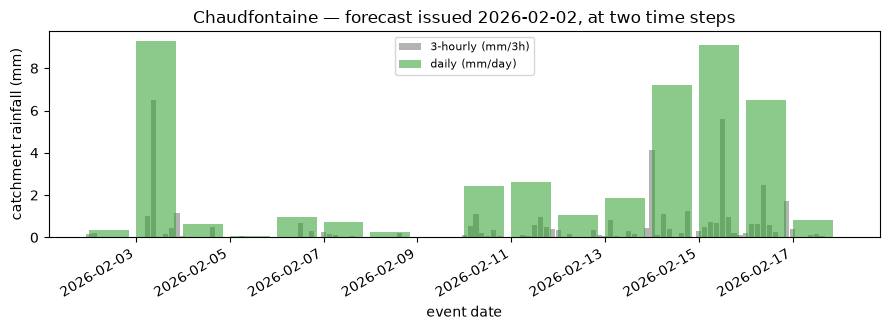

In [19]:
zone = 'Chaudfontaine'
issue = catchments.index[0]

fine_leads = pd.to_timedelta(catchments.loc[:, zone].columns)
daily_leads = pd.to_timedelta(catchments_daily.loc[:, zone].columns)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar([issue + lead for lead in fine_leads], catchments.loc[issue, zone].values,
       width=0.11, color='0.7', label='3-hourly (mm/3h)')
ax.bar([issue + lead for lead in daily_leads], catchments_daily.loc[issue, zone].values,
       width=0.85, alpha=0.55, color='tab:green', align='edge', label='daily (mm/day)')

ax.set(xlabel='event date', ylabel='catchment rainfall (mm)',
       title='%s — forecast issued %s, at two time steps' % (zone, issue.strftime('%Y-%m-%d')))
ax.legend(fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()

---
## 6 · What `Resample` refuses, and what to use instead

`Resample` works in **fixed durations**. A calendar step is not one — a month is 28 to 31
days — so both calendar *leadtimes* and calendar *frequencies* are rejected by name rather
than silently mis-parsed. (`pd.Timedelta` reads `'MS'` as **one millisecond**, which used to
turn a monthly index into a 97 GiB allocation.)

In [20]:
seas5 = MeteoRaster.load(RESOURCES / 'tethys_c3s_ecmwf51_tprate_2026.07.nct', verbose=False)
monthly_point = seas5.get_values_from_latlon(lat=50.5, lon=5.9)

for label, call in [
    ('calendar leadtimes (DateOffset months)',
     lambda: Resample.resample(monthly_point, '1D', 'sum')),
    ("calendar frequency ('MS')",
     lambda: Resample.resample(daily, 'MS', 'sum')),
    ('an unknown type',
     lambda: Resample.resample(daily, '2D', 'median')),
]:
    try:
        call()
    except Exception as error:
        print('%-40s -> %s' % (label, error))

calendar leadtimes (DateOffset months)   -> The leadtime level must hold fixed durations; got object. Calendar leadtimes (pd.DateOffset, as monthly forecasts use) have no fixed length and cannot be resampled to a fixed step - aggregate them with MeteoRaster.adjust_leadtimes or resample_timestep instead.
calendar frequency ('MS')                -> timestep_frequency "MS" is a calendar step, which has no fixed duration and is not supported (pandas would read it as a Timedelta of a different unit). Use a fixed step such as '1D' or '3H'.
an unknown type                          -> Resampling type not implemented: median (expected one of sum, mean, linear, max).


For monthly and seasonal data the tools live on `MeteoRaster` itself, and they *do* take
pandas calendar rules. Both are marked **experimental** and warn on every call, and both
**mutate the raster in place**.

`adjust_leadtimes` relabels calendar leadtimes as relative periods:

In [21]:
adjusted = seas5.copy()
adjusted.verbose = False          # copy() does not carry `verbose` across
adjusted.adjust_leadtimes(period='months')

print('before:', [str(lead) for lead in seas5.leadtimes])
print('after :', [str(lead) for lead in adjusted.leadtimes])

before: ['<DateOffset: months=1>', '<DateOffset: months=2>', '<DateOffset: months=3>', '<DateOffset: months=4>', '<DateOffset: months=5>', '<DateOffset: months=6>']
after : ['<DateOffset: months=0>', '<DateOffset: months=1>', '<DateOffset: months=2>', '<DateOffset: months=3>', '<DateOffset: months=4>', '<DateOffset: months=5>']


meteoraster.py:755: UserWarning: the function adjustLeadTimes() is experimental.


`resample_timestep` aggregates along the **production** axis with a pandas rule and any
reducing function:

In [22]:
monthly = rain.copy()
monthly.verbose = False
monthly.resample_timestep('MS', fun=np.nanmean)

print('productions: %d -> %d' % (rain.data.shape[0], monthly.data.shape[0]))
print('stamps     :', [str(d)[:10] for d in pd.to_datetime(monthly.production_datetime)])
print('shape      :', rain.data.shape, '->', monthly.data.shape)

productions: 7 -> 1
stamps     : ['2026-02-01']
shape      : (7, 1, 129, 29, 57) -> (1, 1, 129, 29, 57)


meteoraster.py:916: UserWarning: the function resample_timestep() is experimental.


> These are a **different code path** from `Resample`, with much less test coverage behind
> them. Easy to conflate: `Resample` rejects `'MS'`, `resample_timestep` requires it.

---

## Summary

| | `Resample.resample` | `MeteoRaster.resample_timestep` |
|---|---|---|
| works on | a production × leadtime `DataFrame` | the raster itself, in place |
| axis | leadtime (forecast) or production (series) | production only |
| steps | fixed durations only (`'1D'`, `'3h'`, `'30min'`) | pandas calendar rules (`'MS'`, `'YS'`) |
| semantics | `sum` / `mean` / `linear` / `max`, documented above | whatever `fun` you pass |
| status | tested in depth | experimental, warns |

And the rule worth remembering: **`sum` for accumulations, `mean` for rates.** Everything
else follows from that.

---
Back to the [index](README.md).